In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt

Dataset tag = example1_Cx6_Ct50
N = 1200
dx solver = 0.01
dt solver = 5e-05
num_steps = 10000
Cx = 6
Ct = 50
Delta x = 0.06
Delta t = 0.0025
Initial mass = 1.0
Initial min = 0.0
Initial max = 0.25

Done
fine data shape = (201, 1200)
obs data shape  = (201, 200)
Delta x = 0.06
Delta t = 0.0025
Initial mass = 1.0
Final mass   = 0.9999999999993975
Mass error   = 6.025180354640725e-13
Final min    = 0.0
Final max    = 0.9287186531366591


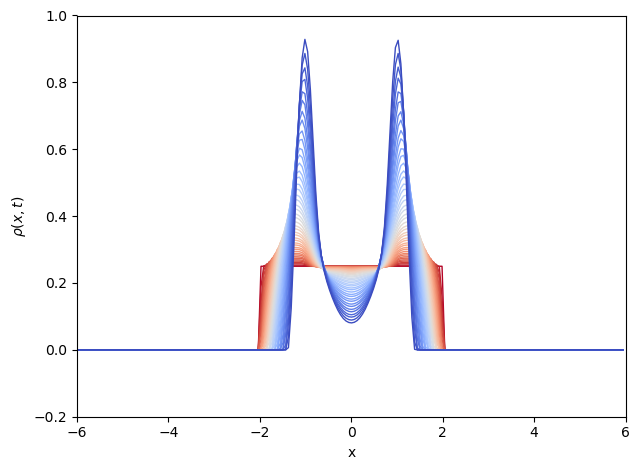

In [2]:
# ============================================================
# Data generation: 
# Method: finite-volume with minmod limiter + SSP-RK3
# Example 1: rho_t = (rho * (kappa * rho + W*rho)_x)_x with W(x) = -5(1-|x|)_+
# Initial condition: rho0 = rho_height * chi[-2,2]
# Cx = 6, Ct = 50
# Method: finite-volume with minmod limiter + SSP-RK3
# ============================================================

kappa = 0.2
m = 2
V = 0.0
L = 6.0
dx = 1e-2
dt = 0.5e-4
T = 0.5
N = int(2 * L / dx)
x = np.linspace(-L + dx / 2, L - dx / 2, N)
num_steps = int(round(T / dt))

# Observation downsampling
Cx = 6
Ct = 50
Delta_x = Cx * dx
Delta_t = Ct * dt
tag = f"example1_Cx{Cx}_Ct{Ct}"
theta = 2.0
rho_height = 0.25

# Potential W(x) = -5(1-|x|)_+
def W(z):
    return -5.0 * np.maximum(1.0 - np.abs(z), 0.0)

# Exact cell-integrated convolution weights
def A_tri(z):
    z = np.asarray(z)
    out = np.zeros_like(z, dtype=float)
    mask1 = (z > -1.0) & (z < 0.0)
    out[mask1] = z[mask1] + 0.5 * z[mask1] ** 2 + 0.5
    mask2 = (z >= 0.0) & (z < 1.0)
    out[mask2] = 0.5 + z[mask2] - 0.5 * z[mask2] ** 2
    out[z >= 1.0] = 1.0
    return out

def int_W(a, b):
    return -5.0 * (A_tri(b) - A_tri(a))

offsets = np.arange(-(N - 1), N) * dx
W_weights = int_W(offsets - dx / 2, offsets + dx / 2)

def conv_W_rho(rho):
    return np.convolve(rho, W_weights, mode="valid")
rho0 = np.zeros_like(x)
rho0[np.abs(x) <= 2.0] = rho_height

def minmod3(a, b, c):
    out = np.zeros_like(a)
    pos = (a > 0.0) & (b > 0.0) & (c > 0.0)
    neg = (a < 0.0) & (b < 0.0) & (c < 0.0)
    out[pos] = np.minimum(np.minimum(a[pos], b[pos]), c[pos])
    out[neg] = np.maximum(np.maximum(a[neg], b[neg]), c[neg])
    return out

def reconstruct(rho):
    rho_ext = np.pad(rho, (1, 1), mode="edge")
    rho_jm = rho_ext[:-2]
    rho_j = rho_ext[1:-1]
    rho_jp = rho_ext[2:]
    slope = minmod3(
        theta * (rho_j - rho_jm) / dx,
        (rho_jp - rho_jm) / (2.0 * dx),
        theta * (rho_jp - rho_j) / dx,
    )
    rho_W = rho - 0.5 * dx * slope
    rho_E = rho + 0.5 * dx * slope
    return rho_W, rho_E

# Finite-volume RHS
def rhs(rho):
    conv = conv_W_rho(rho)
    xi = kappa * rho + conv
    u = -(xi[1:] - xi[:-1]) / dx
    rho_W, rho_E = reconstruct(rho)
    rho_left = rho_E[:-1]
    rho_right = rho_W[1:]
    flux_inner = (np.maximum(u, 0.0) * rho_left + np.minimum(u, 0.0) * rho_right)
    flux = np.zeros(N + 1)
    flux[1:N] = flux_inner
    return -(flux[1:] - flux[:-1]) / dx

def check_cfl(rho):
    conv = conv_W_rho(rho)
    xi = kappa * rho + conv
    u = -(xi[1:] - xi[:-1]) / dx
    a = max(np.max(np.maximum(u, 0.0)), np.max(np.maximum(-u, 0.0)), 1e-14,)
    dt_max = dx / (2.0 * a)
    return dt_max, a

# SSP-RK3
def ssprk3_step(rho):
    rho1 = rho + dt * rhs(rho)
    rho2 = 0.75 * rho + 0.25 * (rho1 + dt * rhs(rho1))
    rho3 = (1.0 / 3.0) * rho + (2.0 / 3.0) * (rho2 + dt * rhs(rho2))
    return rho3

# Time evolution
rho = rho0.copy()
mass0 = dx * np.sum(rho)
fine_snapshots = []
fine_times = []
obs_snapshots = []
obs_times = []

print("Dataset tag =", tag)
print("N =", N)
print("dx solver =", dx)
print("dt solver =", dt)
print("num_steps =", num_steps)
print("Cx =", Cx)
print("Ct =", Ct)
print("Delta x =", Delta_x)
print("Delta t =", Delta_t)
print("Initial mass =", mass0)
print("Initial min =", rho.min())
print("Initial max =", rho.max())

for n in range(num_steps + 1):
    current_t = n * dt
    if n % Ct == 0:
        fine_snapshots.append(rho.copy())
        fine_times.append(current_t)
        obs_snapshots.append(rho[::Cx].copy())
        obs_times.append(current_t)
    if n == num_steps:
        break
    dt_max, amax = check_cfl(rho)
    if dt > dt_max:
        print(
            f"Warning: CFL violated at step {n}, "
            f"dt={dt:.2e}, dt_max={dt_max:.2e}"
        )
    rho_new = ssprk3_step(rho)
    if not np.all(np.isfinite(rho_new)):
        raise RuntimeError("rho became non-finite.")
    if rho_new.min() < -1e-8:
        raise RuntimeError(f"Negative rho detected: {rho_new.min():.3e}")
    rho_new[np.abs(rho_new) < 1e-14] = 0.0
    rho = rho_new

fine_snapshots = np.array(fine_snapshots)
fine_times = np.array(fine_times)
obs_snapshots = np.array(obs_snapshots)
obs_times = np.array(obs_times)
x_obs = x[::Cx]

print("\nDone")
print("fine data shape =", fine_snapshots.shape)
print("obs data shape  =", obs_snapshots.shape)
print("Delta x =", Delta_x)
print("Delta t =", Delta_t)
print("Initial mass =", mass0)
print("Final mass   =", dx * np.sum(rho))
print("Mass error   =", abs(dx * np.sum(rho) - mass0))
print("Final min    =", rho.min())
print("Final max    =", rho.max())


# Plot observed data
os.makedirs("figures_data", exist_ok=True)
num_plot = min(45, len(obs_times))
ids = np.linspace(0, len(obs_times) - 1, num_plot).astype(int)
plt.figure(figsize=(6.5, 4.8))
colors = plt.cm.coolwarm_r(np.linspace(0, 1, len(ids)))
for c, idx in zip(colors, ids):
    plt.plot(x_obs, obs_snapshots[idx], color=c, linewidth=1.0)
plt.xlim(-6, 6)
plt.ylim(-0.2, 1.0)
plt.xlabel("x")
plt.ylabel(r"$\rho(x,t)$")
# plt.title(
#     rf"Example 1 observed data: "
#     rf"$\Delta x={Delta_x:.4f}$, $\Delta t={Delta_t:.4f}$"
# )
plt.tight_layout()
plt.savefig(f"figures_data/{tag}_observed_data.png", dpi=300, bbox_inches="tight",)
plt.savefig(f"figures_data/{tag}_observed_data.pdf", bbox_inches="tight",)
plt.show()

# Save observed data
save_name = f"{tag}.npz"
np.savez(
    save_name,
    x=x,
    x_obs=x_obs,
    fine_times=fine_times,
    obs_times=obs_times,
    fine_snapshots=fine_snapshots,
    obs_snapshots=obs_snapshots,
    L=L,
    T=T,
    dx_solver=dx,
    dt_solver=dt,
    Delta_x=Delta_x,
    Delta_t=Delta_t,
    Cx=Cx,
    Ct=Ct,
    kappa=kappa,
    m=m,
    V=V,
    rho_height=rho_height,
)

N = 960
dx solver = 0.0125
dt solver = 0.0001
num_steps = 15000
Cx = 5
Ct = 250
Delta x = 0.0625
Delta t = 0.025
Initial mass = 1.0
Initial min = 8.718441375982666e-23
Initial max = 0.39905179511026667
Initial E = -0.4098929649455304
step=     0, t=0.0000, min=0.000e+00, max=0.399051, mass=1.0000000000, E=-0.4098992012
step=  1000, t=0.1000, min=0.000e+00, max=0.400695, mass=1.0000000000, E=-0.4162991088
step=  2000, t=0.2000, min=0.000e+00, max=0.404668, mass=1.0000000000, E=-0.4230990200
step=  3000, t=0.3000, min=0.000e+00, max=0.409458, mass=1.0000000000, E=-0.4304100084
step=  4000, t=0.4000, min=0.000e+00, max=0.414510, mass=1.0000000000, E=-0.4383598711
step=  5000, t=0.5000, min=0.000e+00, max=0.419571, mass=1.0000000000, E=-0.4471008048
step=  6000, t=0.6000, min=0.000e+00, max=0.424500, mass=1.0000000000, E=-0.4568128745
step=  7000, t=0.7000, min=0.000e+00, max=0.429331, mass=1.0000000000, E=-0.4677043956
step=  8000, t=0.8000, min=0.000e+00, max=0.434128, mass=1.0000000000,

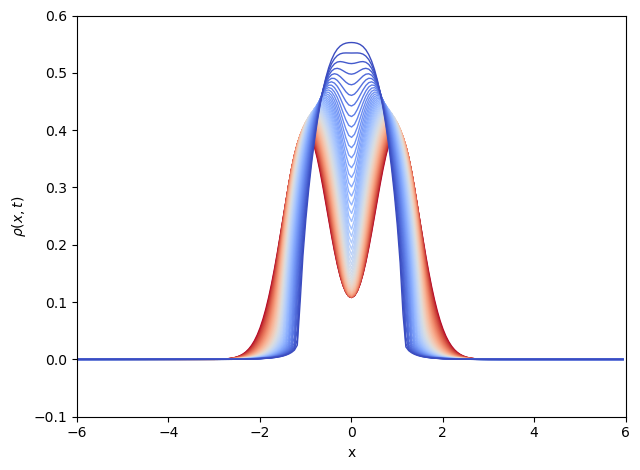

In [3]:
# ============================================================
# Data generation: 
# Method: finite-volume with minmod limiter + SSP-RK3
# Example 2: rho_t = (rho * (kappa * rho + W*rho)_x)_x with W(x) = -2.0 * np.exp(-z**2) / np.sqrt(np.pi) -2.0 * np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)
# Initial condition: rho0 = 0.5 * gaussian_pdf(x, 1.0, 0.5) + 0.5 * gaussian_pdf(x, -1.0, 0.5)
# Cx = 5 Ct = 250
# Method: finite-volume with minmod limiter + SSP-RK3
# ============================================================

m = 3
kappa = 0.48
L = 6.0
dx = 1.25e-2
dt = 1.0e-4
T = 1.5
N = int(round(2 * L / dx))
x = np.linspace(-L + dx / 2, L - dx / 2, N)
num_steps = int(round(T / dt))

# Observation downsampling
Cx = 5
Ct = 250
Delta_x = Cx * dx
Delta_t = Ct * dt
tag = f"example2_sparse_Cx{Cx}_Ct{Ct}"
theta = 1.0

# Potential W(x) = -2.0 * np.exp(-z**2) / np.sqrt(np.pi) -2.0 * np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)
def W(z):
    return (
        -2.0 * np.exp(-z**2) / np.sqrt(np.pi)
        -2.0 * np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)
    )

offsets = np.arange(-(N - 1), N) * dx
W_kernel = dx * W(offsets)

def conv_W_rho(rho):
    return np.convolve(rho, W_kernel, mode="valid")

def gaussian_pdf(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2.0 * np.pi))

rho0 = (0.5 * gaussian_pdf(x, 1.0, 0.5) + 0.5 * gaussian_pdf(x, -1.0, 0.5))
rho0 = rho0 / (dx * np.sum(rho0))
mass0 = dx * np.sum(rho0)

def minmod3(a, b, c):
    out = np.zeros_like(a)
    pos = (a > 0.0) & (b > 0.0) & (c > 0.0)
    neg = (a < 0.0) & (b < 0.0) & (c < 0.0)
    out[pos] = np.minimum(np.minimum(a[pos], b[pos]), c[pos])
    out[neg] = np.maximum(np.maximum(a[neg], b[neg]), c[neg])
    return out

def reconstruct(rho):
    rho_ext = np.pad(rho, (1, 1), mode="edge")
    rho_jm = rho_ext[:-2]
    rho_j = rho_ext[1:-1]
    rho_jp = rho_ext[2:]
    slope = minmod3(
        theta * (rho_j - rho_jm) / dx,
        (rho_jp - rho_jm) / (2.0 * dx),
        theta * (rho_jp - rho_j) / dx,
    )
    rho_W = rho - 0.5 * dx * slope
    rho_E = rho + 0.5 * dx * slope
    return rho_W, rho_E

# Chemical potential and velocity
def compute_xi(rho):
    return kappa * rho ** (m - 1) + conv_W_rho(rho)

def compute_u(rho):
    xi = compute_xi(rho)
    return -(xi[1:] - xi[:-1]) / dx

# Finite-volume RHS
def rhs(rho):
    u = compute_u(rho)

    rho_W, rho_E = reconstruct(rho)

    rho_left = rho_E[:-1]
    rho_right = rho_W[1:]

    flux_inner = (
        np.maximum(u, 0.0) * rho_left
        + np.minimum(u, 0.0) * rho_right
    )

    flux = np.zeros(N + 1)
    flux[1:N] = flux_inner

    return -(flux[1:] - flux[:-1]) / dx

# CFL check
def check_cfl(rho):
    u = compute_u(rho)
    a = max(np.max(np.maximum(u, 0.0)), np.max(np.maximum(-u, 0.0)), 1e-14,)
    dt_max = dx / (2.0 * a)
    return dt_max, a

# SSP-RK3
def ssprk3_step(rho):
    rho1 = rho + dt * rhs(rho)
    rho2 = 0.75 * rho + 0.25 * (rho1 + dt * rhs(rho1))
    rho3 = (1.0 / 3.0) * rho + (2.0 / 3.0) * (rho2 + dt * rhs(rho2))
    return rho3

# Energy
def energy(rho):
    conv = conv_W_rho(rho)
    H = kappa * rho ** m / (m - 1)
    return dx * np.sum(H + 0.5 * rho * conv)

# Time evolution
rho = rho0.copy()
obs_snapshots = []
obs_times = []

print("N =", N)
print("dx solver =", dx)
print("dt solver =", dt)
print("num_steps =", num_steps)
print("Cx =", Cx)
print("Ct =", Ct)
print("Delta x =", Delta_x)
print("Delta t =", Delta_t)
print("Initial mass =", dx * np.sum(rho))
print("Initial min =", rho.min())
print("Initial max =", rho.max())
print("Initial E =", energy(rho))

for n in range(num_steps + 1):
    current_t = n * dt
    if n % Ct == 0:
        obs_snapshots.append(rho[::Cx].copy())
        obs_times.append(current_t)
    if n == num_steps:
        break
    dt_max, amax = check_cfl(rho)
    if dt > dt_max:
        raise RuntimeError(
            f"CFL violated at step {n}: dt={dt:.3e}, dt_max={dt_max:.3e}"
        )
    rho_new = ssprk3_step(rho)
    if not np.all(np.isfinite(rho_new)):
        raise RuntimeError("rho became non-finite.")
    if rho_new.min() < -1e-8:
        raise RuntimeError(f"Negative rho detected: {rho_new.min():.3e}")
    rho_new[np.abs(rho_new) < 1e-14] = 0.0
    rho = rho_new
    if n % 1000 == 0:
        print(
            f"step={n:6d}, t={current_t:.4f}, "
            f"min={rho.min():.3e}, max={rho.max():.6f}, "
            f"mass={dx * np.sum(rho):.10f}, E={energy(rho):.10f}"
        )

obs_snapshots = np.array(obs_snapshots)
obs_times = np.array(obs_times)
x_obs = x[::Cx]

print("\nDone")
print("obs data shape =", obs_snapshots.shape)
print("Delta x =", Delta_x)
print("Delta t =", Delta_t)
print("Final mass =", dx * np.sum(rho))
print("Mass error =", abs(dx * np.sum(rho) - mass0))
print("Final min =", rho.min())
print("Final max =", rho.max())
print("Final E =", energy(rho))

# Plot observed data
os.makedirs("figures_data", exist_ok=True)
plt.figure(figsize=(6.5, 4.8))
colors = plt.cm.coolwarm_r(np.linspace(0, 1, len(obs_times)))
for c, rr in zip(colors, obs_snapshots):
    plt.plot(x_obs, rr, color=c, linewidth=1.0)
plt.xlim(-6, 6)
plt.ylim(-0.1, 0.6)
plt.xlabel("x")
plt.ylabel(r"$\rho(x,t)$")
#plt.title(rf"Observed data: $\Delta x={Delta_x:.4f}$, $\Delta t={Delta_t:.4f}$")

plt.tight_layout()
plt.savefig(f"figures_data/{tag}_observed_data.png", dpi=300, bbox_inches="tight",)
plt.savefig(f"figures_data/{tag}_observed_data.pdf", bbox_inches="tight",)
plt.show()

# Save observed data
save_name = f"{tag}.npz"
np.savez(
    save_name,
    x=x,
    x_obs=x_obs,
    obs_times=obs_times,
    obs_snapshots=obs_snapshots,
    L=L,
    T=T,
    dx_solver=dx,
    dt_solver=dt,
    Delta_x=Delta_x,
    Delta_t=Delta_t,
    Cx=Cx,
    Ct=Ct,
    m=m,
    kappa=kappa,
)

N = 960
dx solver = 0.0125
dt solver = 0.0001
num_steps = 15000
Cx = 2
Ct = 50
Delta x = 0.025
Delta t = 0.005
Initial mass = 1.0
Initial min = 8.718441375982666e-23
Initial max = 0.39905179511026667
Initial E = -0.4098929649455304
step=     0, t=0.0000, min=0.000e+00, max=0.399051, mass=1.0000000000, E=-0.4098992012
step=  1000, t=0.1000, min=0.000e+00, max=0.400695, mass=1.0000000000, E=-0.4162991088
step=  2000, t=0.2000, min=0.000e+00, max=0.404668, mass=1.0000000000, E=-0.4230990200
step=  3000, t=0.3000, min=0.000e+00, max=0.409458, mass=1.0000000000, E=-0.4304100084
step=  4000, t=0.4000, min=0.000e+00, max=0.414510, mass=1.0000000000, E=-0.4383598711
step=  5000, t=0.5000, min=0.000e+00, max=0.419571, mass=1.0000000000, E=-0.4471008048
step=  6000, t=0.6000, min=0.000e+00, max=0.424500, mass=1.0000000000, E=-0.4568128745
step=  7000, t=0.7000, min=0.000e+00, max=0.429331, mass=1.0000000000, E=-0.4677043956
step=  8000, t=0.8000, min=0.000e+00, max=0.434128, mass=1.0000000000, E

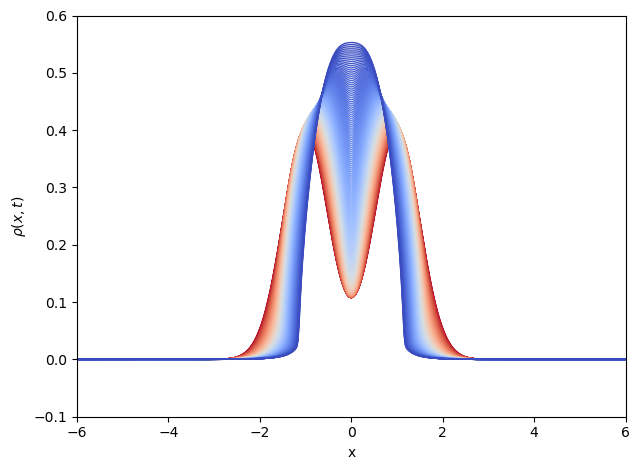

In [4]:
# ============================================================
# Data generation: 
# Method: finite-volume with minmod limiter + SSP-RK3
# Example 2: rho_t = (rho * (kappa * rho + W*rho)_x)_x with W(x) = -2.0 * np.exp(-z**2) / np.sqrt(np.pi) -2.0 * np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)
# Initial condition: rho0 = 0.5 * gaussian_pdf(x, 1.0, 0.5) + 0.5 * gaussian_pdf(x, -1.0, 0.5)
# Method: finite-volume with minmod limiter + SSP-RK3
# Cx = 2 Ct = 50
# ============================================================

m = 3
kappa = 0.48
L = 6.0
dx = 1.25e-2
dt = 1.0e-4
T = 1.5
N = int(round(2 * L / dx))
x = np.linspace(-L + dx / 2, L - dx / 2, N)
num_steps = int(round(T / dt))

# Observation downsampling
Cx = 2
Ct = 50
Delta_x = Cx * dx
Delta_t = Ct * dt
tag = f"example2_sparse_Cx{Cx}_Ct{Ct}"
theta = 1.0

# Potential W(x) = -2.0 * np.exp(-z**2) / np.sqrt(np.pi) -2.0 * np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)
def W(z):
    return (
        -2.0 * np.exp(-z**2) / np.sqrt(np.pi)
        -2.0 * np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)
    )

offsets = np.arange(-(N - 1), N) * dx
W_kernel = dx * W(offsets)

def conv_W_rho(rho):
    return np.convolve(rho, W_kernel, mode="valid")

def gaussian_pdf(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2.0 * np.pi))

rho0 = (0.5 * gaussian_pdf(x, 1.0, 0.5) + 0.5 * gaussian_pdf(x, -1.0, 0.5))
rho0 = rho0 / (dx * np.sum(rho0))
mass0 = dx * np.sum(rho0)

def minmod3(a, b, c):
    out = np.zeros_like(a)
    pos = (a > 0.0) & (b > 0.0) & (c > 0.0)
    neg = (a < 0.0) & (b < 0.0) & (c < 0.0)
    out[pos] = np.minimum(np.minimum(a[pos], b[pos]), c[pos])
    out[neg] = np.maximum(np.maximum(a[neg], b[neg]), c[neg])
    return out

def reconstruct(rho):
    rho_ext = np.pad(rho, (1, 1), mode="edge")
    rho_jm = rho_ext[:-2]
    rho_j = rho_ext[1:-1]
    rho_jp = rho_ext[2:]
    slope = minmod3(
        theta * (rho_j - rho_jm) / dx,
        (rho_jp - rho_jm) / (2.0 * dx),
        theta * (rho_jp - rho_j) / dx,
    )
    rho_W = rho - 0.5 * dx * slope
    rho_E = rho + 0.5 * dx * slope
    return rho_W, rho_E

# Chemical potential and velocity
def compute_xi(rho):
    return kappa * rho ** (m - 1) + conv_W_rho(rho)

def compute_u(rho):
    xi = compute_xi(rho)
    return -(xi[1:] - xi[:-1]) / dx

# Finite-volume RHS
def rhs(rho):
    u = compute_u(rho)

    rho_W, rho_E = reconstruct(rho)

    rho_left = rho_E[:-1]
    rho_right = rho_W[1:]

    flux_inner = (
        np.maximum(u, 0.0) * rho_left
        + np.minimum(u, 0.0) * rho_right
    )

    flux = np.zeros(N + 1)
    flux[1:N] = flux_inner

    return -(flux[1:] - flux[:-1]) / dx

# CFL check
def check_cfl(rho):
    u = compute_u(rho)
    a = max(np.max(np.maximum(u, 0.0)), np.max(np.maximum(-u, 0.0)), 1e-14,)
    dt_max = dx / (2.0 * a)
    return dt_max, a

# SSP-RK3
def ssprk3_step(rho):
    rho1 = rho + dt * rhs(rho)
    rho2 = 0.75 * rho + 0.25 * (rho1 + dt * rhs(rho1))
    rho3 = (1.0 / 3.0) * rho + (2.0 / 3.0) * (rho2 + dt * rhs(rho2))
    return rho3

# Energy
def energy(rho):
    conv = conv_W_rho(rho)
    H = kappa * rho ** m / (m - 1)
    return dx * np.sum(H + 0.5 * rho * conv)

# Time evolution
rho = rho0.copy()
obs_snapshots = []
obs_times = []

print("N =", N)
print("dx solver =", dx)
print("dt solver =", dt)
print("num_steps =", num_steps)
print("Cx =", Cx)
print("Ct =", Ct)
print("Delta x =", Delta_x)
print("Delta t =", Delta_t)
print("Initial mass =", dx * np.sum(rho))
print("Initial min =", rho.min())
print("Initial max =", rho.max())
print("Initial E =", energy(rho))

for n in range(num_steps + 1):
    current_t = n * dt
    if n % Ct == 0:
        obs_snapshots.append(rho[::Cx].copy())
        obs_times.append(current_t)
    if n == num_steps:
        break
    dt_max, amax = check_cfl(rho)
    if dt > dt_max:
        raise RuntimeError(
            f"CFL violated at step {n}: dt={dt:.3e}, dt_max={dt_max:.3e}"
        )
    rho_new = ssprk3_step(rho)
    if not np.all(np.isfinite(rho_new)):
        raise RuntimeError("rho became non-finite.")
    if rho_new.min() < -1e-8:
        raise RuntimeError(f"Negative rho detected: {rho_new.min():.3e}")
    rho_new[np.abs(rho_new) < 1e-14] = 0.0
    rho = rho_new
    if n % 1000 == 0:
        print(
            f"step={n:6d}, t={current_t:.4f}, "
            f"min={rho.min():.3e}, max={rho.max():.6f}, "
            f"mass={dx * np.sum(rho):.10f}, E={energy(rho):.10f}"
        )

obs_snapshots = np.array(obs_snapshots)
obs_times = np.array(obs_times)
x_obs = x[::Cx]

print("\nDone")
print("obs data shape =", obs_snapshots.shape)
print("Delta x =", Delta_x)
print("Delta t =", Delta_t)
print("Final mass =", dx * np.sum(rho))
print("Mass error =", abs(dx * np.sum(rho) - mass0))
print("Final min =", rho.min())
print("Final max =", rho.max())
print("Final E =", energy(rho))

# Plot observed data
os.makedirs("figures_data", exist_ok=True)
plt.figure(figsize=(6.5, 4.8))
colors = plt.cm.coolwarm_r(np.linspace(0, 1, len(obs_times)))
for c, rr in zip(colors, obs_snapshots):
    plt.plot(x_obs, rr, color=c, linewidth=1.0)
plt.xlim(-6, 6)
plt.ylim(-0.1, 0.6)
plt.xlabel("x")
plt.ylabel(r"$\rho(x,t)$")
# plt.title(rf"Observed data: $\Delta x={Delta_x:.4f}$, $\Delta t={Delta_t:.4f}$")

plt.tight_layout()
plt.savefig(f"figures_data/{tag}_observed_data.png", dpi=300, bbox_inches="tight",)
plt.savefig(f"figures_data/{tag}_observed_data.pdf", bbox_inches="tight",)
plt.show()

# Save observed data
save_name = f"{tag}.npz"
np.savez(
    save_name,
    x=x,
    x_obs=x_obs,
    obs_times=obs_times,
    obs_snapshots=obs_snapshots,
    L=L,
    T=T,
    dx_solver=dx,
    dt_solver=dt,
    Delta_x=Delta_x,
    Delta_t=Delta_t,
    Cx=Cx,
    Ct=Ct,
    m=m,
    kappa=kappa,
)